In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
from sklearn.decomposition import PCA

In [2]:
df = pd.read_csv("segmentation data.csv")
df.columns = df.columns.str.strip()
print(df.shape)
df.head()

(2000, 8)


,ID,Sex,Marital status,Age,Education,Income,Occupation,Settlement size
0,100000001,0,0,67,2,124670,1,2
1,100000002,1,1,22,1,150773,1,2
2,100000003,0,0,49,1,89210,0,0
3,100000004,0,0,45,1,171565,1,1
4,100000005,0,0,53,1,149031,1,1


In [3]:
df.isnull().sum()

ID                 0
Sex                0
Marital status     0
Age                0
Education          0
Income             0
Occupation         0
Settlement size    0
dtype: int64

In [4]:
df = df.drop_duplicates()

print("Final Shape:", df.shape)

Final Shape: (2000, 8)


In [5]:
print("Shape:", df.shape)
df.head()
df.info()
df.describe(include='all')

Shape: (2000, 8)
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   ID               2000 non-null   int64
 1   Sex              2000 non-null   int64
 2   Marital status   2000 non-null   int64
 3   Age              2000 non-null   int64
 4   Education        2000 non-null   int64
 5   Income           2000 non-null   int64
 6   Occupation       2000 non-null   int64
 7   Settlement size  2000 non-null   int64
dtypes: int64(8)
memory usage: 125.1 KB


,ID,Sex,Marital status,Age,Education,Income,Occupation,Settlement size
count,2.000000e+03,2000.000000,2000.000000,2000.000000,2000.00000,2000.000000,2000.000000,2000.000000
mean,1.000010e+08,0.457000,0.496500,35.909000,1.03800,120954.419000,0.810500,0.739000
std,5.774946e+02,0.498272,0.500113,11.719402,0.59978,38108.824679,0.638587,0.812533
min,1.000000e+08,0.000000,0.000000,18.000000,0.00000,35832.000000,0.000000,0.000000
25%,1.000005e+08,0.000000,0.000000,27.000000,1.00000,97663.250000,0.000000,0.000000
50%,1.000010e+08,0.000000,0.000000,33.000000,1.00000,115548.500000,1.000000,1.000000
75%,1.000015e+08,1.000000,1.000000,42.000000,1.00000,138072.250000,1.000000,1.000000
max,1.000020e+08,1.000000,1.000000,76.000000,3.00000,309364.000000,2.000000,2.000000


In [6]:
df.isnull().sum()

ID                 0
Sex                0
Marital status     0
Age                0
Education          0
Income             0
Occupation         0
Settlement size    0
dtype: int64

In [7]:
# Missing value percentage
(df.isnull().sum() / len(df)) * 100

ID                 0.0
Sex                0.0
Marital status     0.0
Age                0.0
Education          0.0
Income             0.0
Occupation         0.0
Settlement size    0.0
dtype: float64

In [8]:
df = df.dropna()

print("Shape after removing missing values:", df.shape)

Shape after removing missing values: (2000, 8)


In [9]:
df = df.drop(columns=['ID'], errors='ignore')


X = df.select_dtypes(include=np.number)

print("Selected features:", X.columns.tolist())
X.head()

Selected features: ['Sex', 'Marital status', 'Age', 'Education', 'Income', 'Occupation', 'Settlement size']


,Sex,Marital status,Age,Education,Income,Occupation,Settlement size
0,0,0,67,2,124670,1,2
1,1,1,22,1,150773,1,2
2,0,0,49,1,89210,0,0
3,0,0,45,1,171565,1,1
4,0,0,53,1,149031,1,1


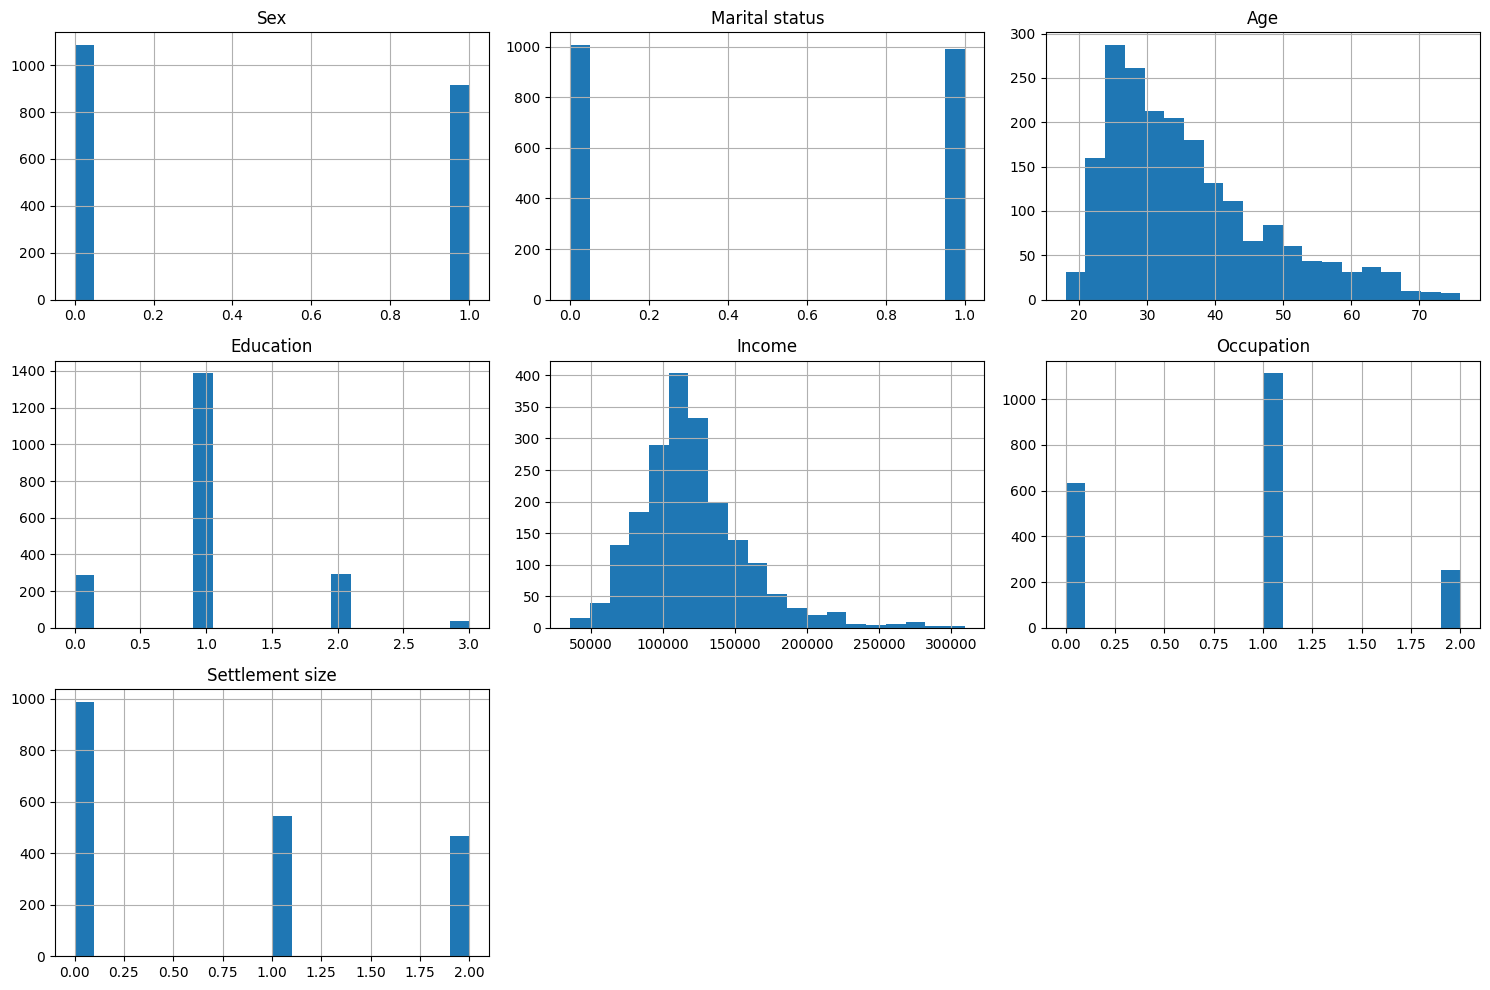

In [10]:
df.hist(figsize=(15, 10), bins=20)
plt.tight_layout()
plt.show()

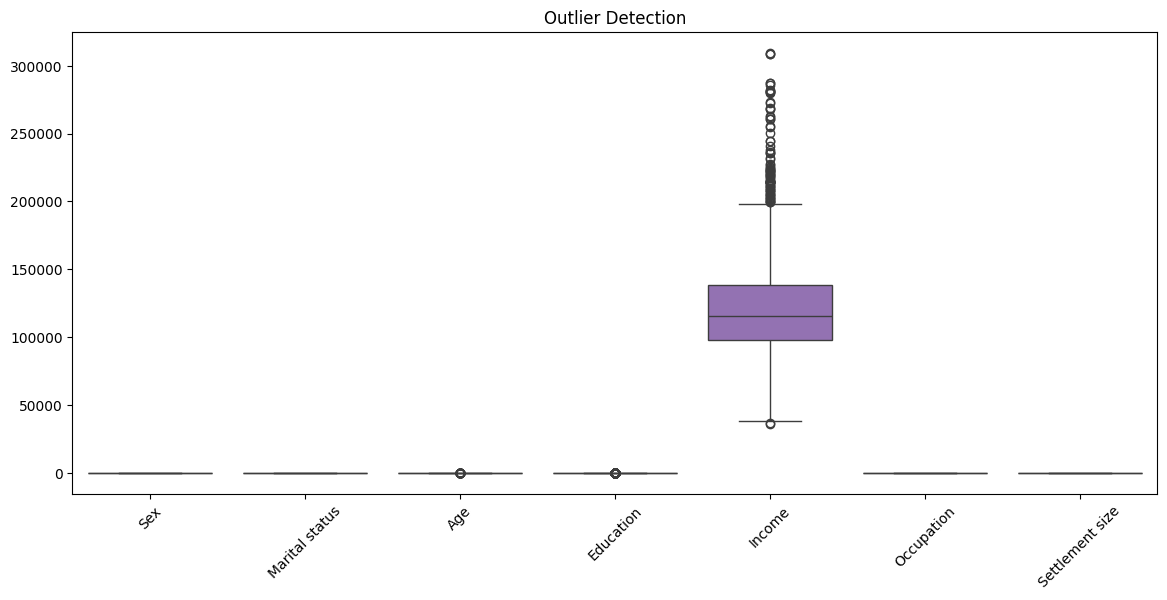

In [11]:
plt.figure(figsize=(14, 6))

sns.boxplot(data=X)

plt.xticks(rotation=45)
plt.title("Outlier Detection")
plt.show()

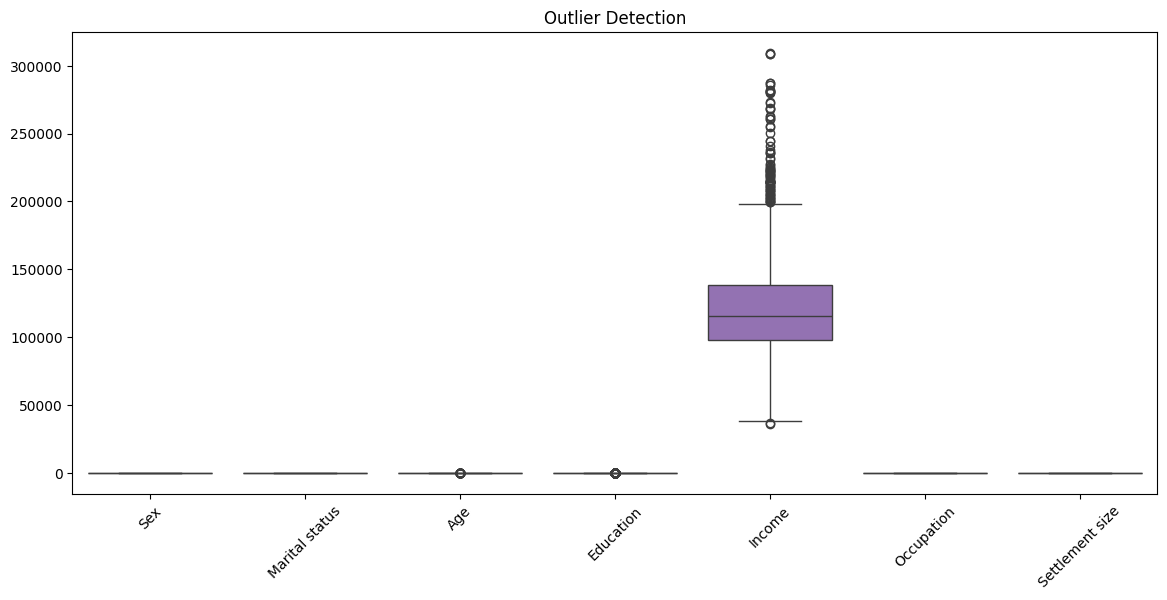

In [12]:
plt.figure(figsize=(14, 6))

sns.boxplot(data=X)

plt.xticks(rotation=45)
plt.title("Outlier Detection")
plt.show()

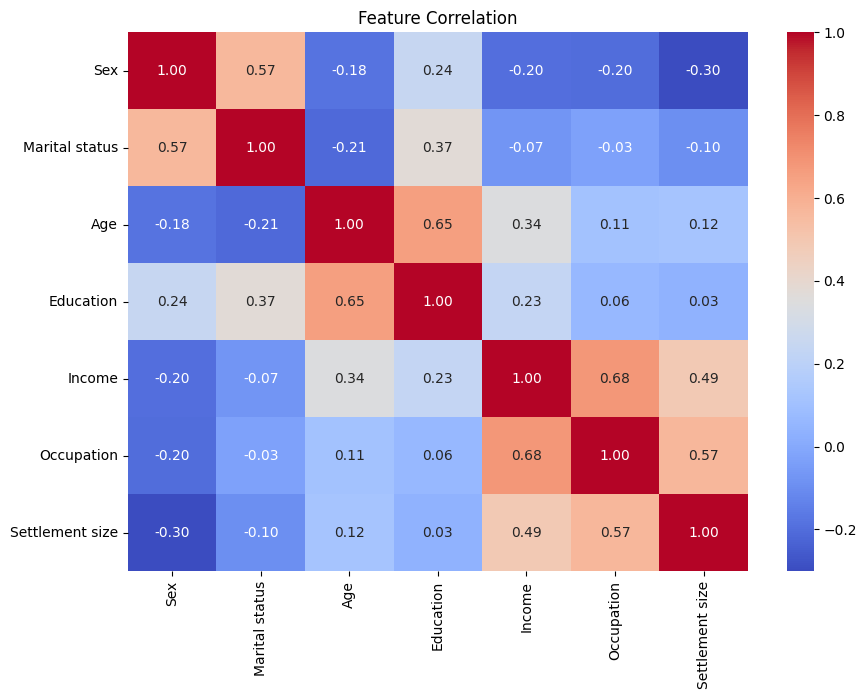

In [13]:
plt.figure(figsize=(10, 7))

sns.heatmap(X.corr(), annot=True, cmap='coolwarm', fmt='.2f')

plt.title("Feature Correlation")
plt.show()

In [14]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Original shape:", X.shape)
print("Scaled shape:", X_scaled.shape)

Original shape: (2000, 7)
Scaled shape: (2000, 7)


In [15]:
from sklearn.cluster import KMeans

wcss = []

for k in range(1, 11):

    kmeans = KMeans(
        n_clusters=k,
        init='k-means++',
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    wcss.append(kmeans.inertia_)

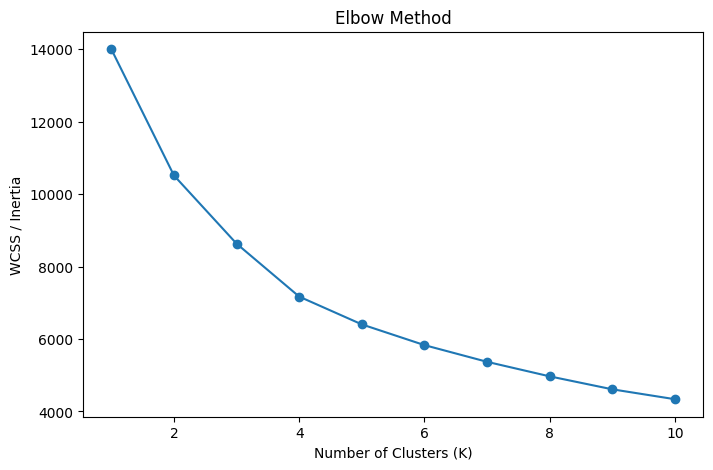

In [16]:
plt.figure(figsize=(8, 5))

plt.plot(range(1, 11), wcss, marker='o')

plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS / Inertia")
plt.title("Elbow Method")

plt.show()

In [17]:
from sklearn.metrics import silhouette_score

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 2, Silhouette Score = 0.2498
K = 3, Silhouette Score = 0.2712
K = 4, Silhouette Score = 0.2688
K = 5, Silhouette Score = 0.2542
K = 6, Silhouette Score = 0.2632
K = 7, Silhouette Score = 0.2653
K = 8, Silhouette Score = 0.2870
K = 9, Silhouette Score = 0.3042
K = 10, Silhouette Score = 0.3014


In [18]:
kmeans = KMeans(
    n_clusters=3,
    init='k-means++',
    random_state=42,
    n_init=10
)

df['Cluster'] = kmeans.fit_predict(X_scaled)

df.head()

,Sex,Marital status,Age,Education,Income,Occupation,Settlement size,Cluster
0,0,0,67,2,124670,1,2,1
1,1,1,22,1,150773,1,2,2
2,0,0,49,1,89210,0,0,0
3,0,0,45,1,171565,1,1,0
4,0,0,53,1,149031,1,1,0


In [19]:
df['Cluster'].value_counts().sort_index()

Cluster
0    859
1    282
2    859
Name: count, dtype: int64

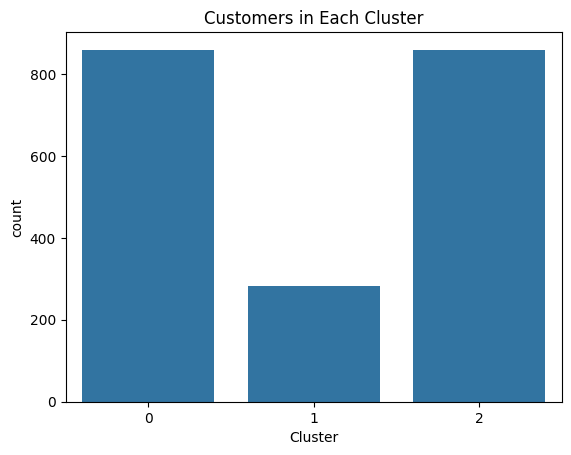

In [20]:
sns.countplot(data=df, x='Cluster')

plt.title("Customers in Each Cluster")
plt.show()

In [21]:
cluster_analysis = df.groupby('Cluster').mean(numeric_only=True)

cluster_analysis

,Sex,Marital status,Age,Education,Income,Occupation,Settlement size
Cluster,,,,,,,
0,0.005821,0.129220,35.387660,0.703143,125964.504075,0.944121,1.023283
1,0.492908,0.666667,55.078014,2.078014,158786.875887,1.134752,1.109929
2,0.896391,0.807916,30.137369,1.031432,103524.365541,0.570431,0.332945


In [22]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    X_pca,
    columns=['PCA1', 'PCA2']
)

pca_df['Cluster'] = df['Cluster'].values

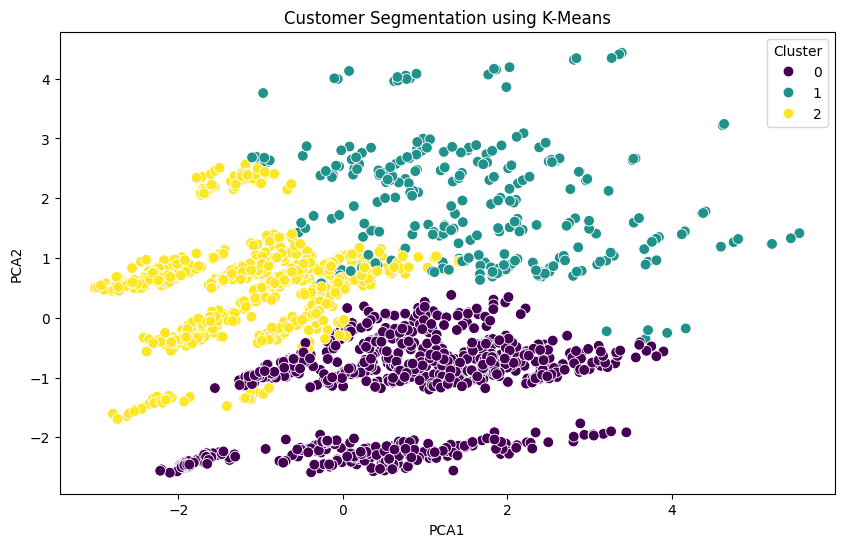

In [23]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=pca_df,
    x='PCA1',
    y='PCA2',
    hue='Cluster',
    palette='viridis',
    s=60
)

plt.title("Customer Segmentation using K-Means")
plt.show()

In [24]:
# Save K-Means Results

df.to_csv("KMeans_Clustering_Results.csv", index=False)

print("K-Means Results Saved Successfully!")

K-Means Results Saved Successfully!
